In [1]:
pip install faker pandas numpy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\agusb\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import random
from datetime import datetime, timedelta
import numpy as np
import pandas as pd
from faker import Faker
import logging

In [3]:
fake = Faker('es_ES')
Faker.seed(42)
random.seed(42)
np.random.seed(42)

In [4]:
# Log de carga: cada paso queda registrado en pantalla y en el archivo carga_datos.log
logging.basicConfig(level=logging.INFO, format='%(asctime)s | %(levelname)s | %(message)s',
                    handlers=[logging.FileHandler('carga_datos.log', mode='w', encoding='utf-8'),
                              logging.StreamHandler()], force=True)
log = logging.getLogger('fleetlogix')
log.info('Inicio de la generación de datos')

2026-11-16 20:23:30,839 | INFO | Inicio de la generación de datos


# Tabla vehicles
Cada tipo de vehículo tiene su rango de capacidad y sus combustibles posibles. La fecha de compra es anterior al inicio de los viajes (octubre 2024).

In [5]:
# Reglas de negocio para cada tipo de vehículo
vehicle_configs = [
    {'type': 'Camión Grande',  'min_cap': 8000.0, 'max_cap': 15000.0, 'fuels': ['Diesel']},
    {'type': 'Camión Mediano', 'min_cap': 3500.0, 'max_cap': 7999.0,  'fuels': ['Diesel', 'Gasolina']},
    {'type': 'Van',            'min_cap': 800.0,  'max_cap': 3499.0,  'fuels': ['Diesel', 'Gasolina', 'Eléctrico']},
    {'type': 'Motocicleta',    'min_cap': 50.0,   'max_cap': 250.0,   'fuels': ['Gasolina', 'Eléctrico']},
]

vehicles = []
used_plates = set()

In [6]:
# Función para asegurar que las patentes sean únicas
def generate_unique_plate():
    # Genera una patente al azar y se asegura de que no se repita
    while True:
        plate = fake.bothify(text='??###??').upper()   # letras (?) y números (#) al azar
        if plate not in used_plates:
            used_plates.add(plate)
            return plate

In [7]:
# Bucle para generar exactamente los 200 registros pedidos
for i in range(1, 201):
    config = random.choice(vehicle_configs)                                   # tipo de vehículo al azar
    capacity_kg = round(random.uniform(config['min_cap'], config['max_cap']), 2)  # capacidad según el tipo
    fuel_type = random.choice(config['fuels'])                                # combustible según el tipo
    acquisition_date = fake.date_between(start_date=datetime(2020, 1, 1), end_date=datetime(2024, 9, 30))
    status = np.random.choice(['active', 'maintenance', 'inactive'], p=[0.85, 0.10, 0.05])

    vehicles.append({
        'vehicle_id': i,
        'license_plate': generate_unique_plate(),
        'vehicle_type': config['type'],
        'capacity_kg': capacity_kg,
        'fuel_type': fuel_type,
        'acquisition_date': acquisition_date.strftime('%Y-%m-%d'),
        'status': status,
    })

In [8]:
# Convertir a DataFrame y guardar en CSV
df_vehicles = pd.DataFrame(vehicles)
df_vehicles.to_csv('vehicles.csv', index=False)
log.info(f'vehicles: {len(df_vehicles)} registros generados')
df_vehicles.head()

2026-11-16 20:23:30,910 | INFO | vehicles: 200 registros generados


,vehicle_id,license_plate,vehicle_type,capacity_kg,fuel_type,acquisition_date,status
0,1,OI043VG,Camión Grande,8175.08,Diesel,2020-12-11,active
1,2,CB196FN,Camión Mediano,4504.23,Diesel,2024-08-21,inactive
2,3,JM890TP,Camión Grande,12133.45,Diesel,2021-12-23,active
3,4,LR637ZA,Camión Grande,8655.87,Diesel,2024-08-20,active
4,5,JN654WV,Camión Grande,11928.72,Diesel,2021-05-11,active


# Tabla Drivers
Código de empleado y licencia únicos. La licencia vence **después** del último viaje simulado (septiembre 2026), así todos los conductores tienen licencia válida mientras manejan.

In [9]:
drivers = []
used_employee_codes = set()
used_license_numbers = set()

start_hire_date = datetime(2021, 1, 1)
end_hire_date = datetime(2026, 6, 1)

In [10]:
# Bucle para generar exactamente los 400 registros de conductores
for i in range(1, 401):
    # Código de empleado único
    while True:
        employee_code = f'EMP-{random.randint(1000, 9999)}'
        if employee_code not in used_employee_codes:
            used_employee_codes.add(employee_code)
            break

    # Número de licencia único
    while True:
        license_number = f'LIC-{random.randint(10000000, 99999999)}'
        if license_number not in used_license_numbers:
            used_license_numbers.add(license_number)
            break

    hire_date = start_hire_date + timedelta(days=random.randint(0, (end_hire_date - start_hire_date).days))
    # Licencia vigente: vence entre octubre 2026 y 2030 (siempre después de la contratación)
    license_expiry = datetime(2026, 10, 1) + timedelta(days=random.randint(0, 1460))

    drivers.append({
        'driver_id': i,
        'employee_code': employee_code,
        'first_name': fake.first_name(),
        'last_name': fake.last_name(),
        'license_number': license_number,
        'license_expiry': license_expiry.strftime('%Y-%m-%d'),
        'phone': f'+54911{random.randint(10000000, 99999999)}',
        'hire_date': hire_date.strftime('%Y-%m-%d'),
        'status': np.random.choice(['active', 'inactive'], p=[0.90, 0.10]),
    })

In [11]:
# Convertir a DataFrame y guardar en CSV
df_drivers = pd.DataFrame(drivers)
df_drivers.to_csv('drivers.csv', index=False)
log.info(f'drivers: {len(df_drivers)} registros generados')
df_drivers.head()

2026-11-16 20:23:31,009 | INFO | drivers: 400 registros generados


,driver_id,employee_code,first_name,last_name,license_number,license_expiry,phone,hire_date,status
0,1,EMP-8613,Esmeralda,Ayala,LIC-86483924,2030-06-30,+5491160867083,2024-06-03,active
1,2,EMP-6511,Ileana,Bilbao,LIC-13852048,2028-07-27,+5491134406132,2023-10-10,active
2,3,EMP-8988,Lalo,Salazar,LIC-38470244,2028-03-13,+5491155679506,2022-12-28,active
3,4,EMP-5581,Gisela,Rodrigo,LIC-90014570,2028-04-18,+5491184597009,2024-12-07,active
4,5,EMP-1166,Amalia,Salamanca,LIC-79340535,2027-10-27,+5491121490777,2026-04-26,active


# Tabla Routes
Hay 20 combinaciones origen → destino entre las 5 ciudades. Para llegar a 50 rutas, se recorren las combinaciones varias veces y cada ruta tiene una variación de distancia, duración y peaje (por ejemplo, otra autopista o con distintos peajes).

In [12]:
random.seed(42)
np.random.seed(42)

cities = ['Buenos Aires', 'Córdoba', 'Rosario', 'Mendoza', 'San Miguel de Tucumán']

# Distancia (km), duración (h) y peaje base aproximados entre cada par de ciudades
city_distances = {
    ('Buenos Aires', 'Córdoba'): (700, 8.5, 4500),
    ('Buenos Aires', 'Rosario'): (300, 3.5, 2000),
    ('Buenos Aires', 'Mendoza'): (1050, 13.0, 6500),
    ('Buenos Aires', 'San Miguel de Tucumán'): (1250, 15.0, 7500),
    ('Córdoba', 'Rosario'): (400, 4.5, 2500),
    ('Córdoba', 'Mendoza'): (600, 7.5, 3500),
    ('Córdoba', 'San Miguel de Tucumán'): (550, 7.0, 3000),
    ('Rosario', 'Mendoza'): (850, 10.0, 5000),
    ('Rosario', 'San Miguel de Tucumán'): (950, 11.5, 5500),
    ('Mendoza', 'San Miguel de Tucumán'): (980, 12.0, 6000),
}

routes = []
route_id = 1

In [13]:
while route_id <= 50:                       # repetimos las 20 combinaciones hasta llegar a 50
    for c1 in cities:
        for c2 in cities:
            if c1 != c2 and route_id <= 50:  # origen y destino distintos
                pair = (c1, c2) if (c1, c2) in city_distances else (c2, c1)
                base_dist, base_dur, base_toll = city_distances[pair]
                routes.append({
                    'route_id': route_id,
                    'route_code': f'RTE-{100 + route_id}',
                    'origin_city': c1,
                    'destination_city': c2,
                    'distance_km': round(base_dist * random.uniform(0.95, 1.05), 2),
                    'estimated_duration_hours': round(base_dur * random.uniform(0.95, 1.05), 2),
                    'toll_cost': round(base_toll * random.uniform(0.90, 1.10), 2),
                })
                route_id += 1

In [14]:
# Convertir a DataFrame y guardar en CSV
df_routes = pd.DataFrame(routes)
df_routes.to_csv('routes.csv', index=False)
log.info(f'routes: {len(df_routes)} registros generados')
df_routes.head()

2026-11-16 20:23:31,066 | INFO | routes: 50 registros generados


,route_id,route_code,origin_city,destination_city,distance_km,estimated_duration_hours,toll_cost
0,1,RTE-101,Buenos Aires,Córdoba,709.76,8.10,4297.53
1,2,RTE-102,Buenos Aires,Rosario,291.70,3.58,2070.68
2,3,RTE-103,Buenos Aires,Mendoza,1091.18,12.46,6398.50
3,4,RTE-104,Buenos Aires,San Miguel de Tucumán,1191.22,14.58,7508.03
4,5,RTE-105,Córdoba,Buenos Aires,666.86,8.24,4634.90


# Tabla Trips
### Funciones `generate_trips()` y `get_hourly_distribution()`

**`get_hourly_distribution()`** devuelve la probabilidad de que un viaje salga a cada hora del día. No todas las horas son iguales: la mayoría de los camiones sale a la mañana (pico entre las 6 y las 9) y hay un segundo pico después del mediodía (13 a 15). De noche casi no salen. Los 24 pesos se dividen por su suma para que den 1 y se puedan usar como probabilidades.

**`generate_trips()`** arma los 100.000 viajes en 4 pasos:
1. **Sortea** para cada viaje un día dentro de los 2 años de operación (oct-2024 a sep-2026), una hora usando `get_hourly_distribution()`, una ruta y un vehículo activo. Lo hace todo junto con numpy, que es mucho más rápido que sortear de a uno.
2. **Elige un conductor que ya estaba contratado** ese día: ordena a los conductores por fecha de contratación y solo sortea entre los que entraron antes de la salida.
3. **Calcula la llegada**: duración estimada de la ruta × un factor entre 0,9 y 1,3 (tráfico y demoras). Así `arrival_datetime` siempre es mayor que `departure_datetime`.
4. **Calcula peso y combustible**: el peso es entre el 30% y el 95% de la capacidad del vehículo, y el combustible depende de los km de la ruta.

In [15]:
def get_hourly_distribution():
    # Peso de cada hora del día (0 a 23): picos a la mañana y después del mediodía
    weights = [
        0.01, 0.01, 0.01, 0.01, 0.02, 0.04,  # 00-05
        0.09, 0.12, 0.11, 0.08, 0.06, 0.05,  # 06-11
        0.04, 0.07, 0.08, 0.06, 0.05, 0.04,  # 12-17
        0.03, 0.02, 0.02, 0.01, 0.01, 0.01,  # 18-23
    ]
    return np.array(weights) / sum(weights)   # que sumen 1 para usarlas como probabilidades


def generate_trips(n_trips=100000):
    random.seed(42)
    np.random.seed(42)

    # Datos de las tablas maestras
    active_vehicle_ids = df_vehicles[df_vehicles['status'] != 'inactive']['vehicle_id'].values
    route_dict = df_routes.set_index('route_id')[['estimated_duration_hours', 'distance_km']].to_dict('index')
    v_cap_dict = df_vehicles.set_index('vehicle_id')['capacity_kg'].to_dict()

    # Conductores activos ordenados por fecha de contratación
    drv = df_drivers[df_drivers['status'] == 'active'].copy()
    drv['hire_date'] = pd.to_datetime(drv['hire_date'])
    drv = drv.sort_values('hire_date')
    drv_ids = drv['driver_id'].values
    drv_hire = drv['hire_date'].values

    # 1. Sorteo masivo con numpy
    start_trips = datetime(2024, 10, 1)
    end_trips = datetime(2026, 9, 30)
    total_days = (end_trips - start_trips).days
    random_days = np.random.randint(0, total_days, size=n_trips)
    selected_hours = np.random.choice(np.arange(24), size=n_trips, p=get_hourly_distribution())
    selected_minutes = np.random.randint(0, 60, size=n_trips)
    selected_v_ids = np.random.choice(active_vehicle_ids, size=n_trips)
    selected_r_ids = np.random.choice(list(route_dict.keys()), size=n_trips)

    trips = []
    for i in range(n_trips):
        dep_dt = start_trips + timedelta(days=int(random_days[i]), hours=int(selected_hours[i]),
                                         minutes=int(selected_minutes[i]))

        # 2. Conductor ya contratado: solo los que entraron antes de la salida
        hired = np.searchsorted(drv_hire, np.datetime64(dep_dt), side='right')
        driver_id = int(drv_ids[random.randrange(hired)])

        # 3. Llegada = salida + duración estimada x factor de demoras
        r_info = route_dict[selected_r_ids[i]]
        actual_dur = r_info['estimated_duration_hours'] * random.uniform(0.9, 1.3)
        arr_dt = dep_dt + timedelta(hours=actual_dur)

        # 4. Peso y combustible
        v_cap = v_cap_dict[selected_v_ids[i]]
        trips.append({
            'trip_id': i + 1,
            'vehicle_id': int(selected_v_ids[i]),
            'driver_id': driver_id,
            'route_id': int(selected_r_ids[i]),
            'departure_datetime': dep_dt.strftime('%Y-%m-%d %H:%M:%S'),
            'arrival_datetime': arr_dt.strftime('%Y-%m-%d %H:%M:%S'),
            'fuel_consumed_liters': round((r_info['distance_km'] / 100.0) * random.uniform(12, 32), 2),
            'total_weight_kg': round(v_cap * random.uniform(0.3, 0.95), 2),
            'status': 'completed',
        })
    return pd.DataFrame(trips)


log.info('Generando trips...')
df_trips = generate_trips()
df_trips.to_csv('trips.csv', index=False)
log.info(f'trips: {len(df_trips)} registros generados')
df_trips.head()

2026-11-16 20:23:31,092 | INFO | Generando trips...
2026-11-16 20:23:33,513 | INFO | trips: 100000 registros generados


,trip_id,vehicle_id,driver_id,route_id,departure_datetime,arrival_datetime,fuel_consumed_liters,total_weight_kg,status
0,1,127,85,23,2025-01-11 10:46:00,2025-01-11 22:02:29,178.78,409.39,completed
1,2,49,215,14,2025-12-10 12:51:00,2025-12-10 21:48:20,180.45,792.95,completed
2,3,157,160,18,2025-06-28 10:43:00,2025-06-28 16:57:34,74.09,79.12,completed
3,4,28,304,36,2025-01-15 06:56:00,2025-01-15 19:53:55,261.57,171.54,completed
4,5,190,197,38,2024-12-11 06:20:00,2024-12-11 13:15:02,127.72,10640.84,completed


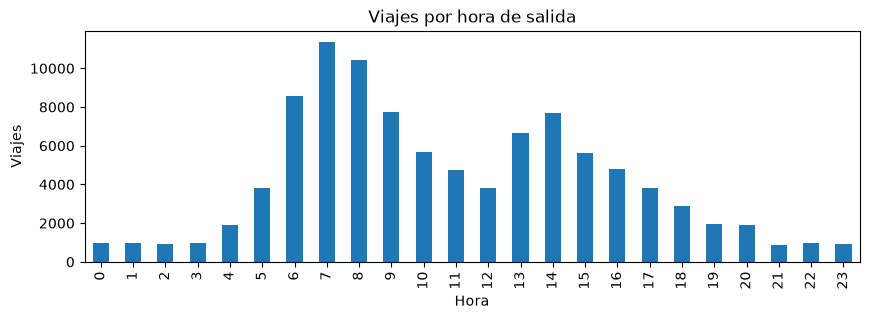

In [16]:
# Distribución de salidas por hora: se ven los picos de get_hourly_distribution()
pd.to_datetime(df_trips['departure_datetime']).dt.hour.value_counts().sort_index().plot(
    kind='bar', figsize=(10, 3), title='Viajes por hora de salida', xlabel='Hora', ylabel='Viajes');

# Tabla Deliveries
Cada viaje tiene entre 2 y 6 entregas (4 es lo más probable). El peso del viaje se reparte entre sus entregas, y cada entrega ocurre después de que llega el camión.

In [17]:
random.seed(42)
np.random.seed(42)

deliveries = []
delivery_id = 1
log.info('Generando deliveries...')

trip_records = df_trips[['trip_id', 'arrival_datetime', 'total_weight_kg']].to_dict('records')

for trip in trip_records:
    arr_dt = datetime.strptime(trip['arrival_datetime'], '%Y-%m-%d %H:%M:%S')

    # Cantidad de entregas del viaje: entre 2 y 6, con 4 como la más probable
    num_deliveries = np.random.choice([2, 3, 4, 5, 6], p=[0.10, 0.20, 0.40, 0.20, 0.10])

    # Repartir el peso del viaje entre sus entregas
    delivery_weights = np.random.dirichlet(np.ones(num_deliveries)) * trip['total_weight_kg']

    for j in range(num_deliveries):
        sched_dt = arr_dt + timedelta(hours=random.uniform(0.5, 12.0))         # programada después de llegar
        del_dt = sched_dt + timedelta(hours=random.uniform(-0.5, 3.0))         # a veces un poco antes o después
        if del_dt < arr_dt:                                                    # nunca antes de que llegue el camión
            del_dt = arr_dt + timedelta(minutes=random.randint(10, 180))

        status = np.random.choice(['delivered', 'failed', 'pending'], p=[0.92, 0.05, 0.03])

        deliveries.append({
            'delivery_id': delivery_id,
            'trip_id': trip['trip_id'],
            'tracking_number': f'TRK-{delivery_id:08d}{fake.bothify(text="??").upper()}',  # único por construcción
            'customer_name': fake.name(),
            'delivery_address': fake.street_address(),
            'package_weight_kg': round(delivery_weights[j], 2),
            'scheduled_datetime': sched_dt.strftime('%Y-%m-%d %H:%M:%S'),
            'delivered_datetime': del_dt.strftime('%Y-%m-%d %H:%M:%S'),
            'delivery_status': status,
            'recipient_signature': fake.name() if status == 'delivered' else 'N/A',
        })
        delivery_id += 1

df_deliveries = pd.DataFrame(deliveries)
df_deliveries.to_csv('deliveries.csv', index=False)
log.info(f'deliveries: {len(df_deliveries)} registros generados')
df_deliveries.head()

2026-11-16 20:23:36,618 | INFO | Generando deliveries...
2026-11-16 20:24:33,384 | INFO | deliveries: 400461 registros generados


,delivery_id,trip_id,tracking_number,customer_name,delivery_address,package_weight_kg,scheduled_datetime,delivered_datetime,delivery_status,recipient_signature
0,1,1,TRK-00000001LE,Juan Francisco Pinto Coloma,Camino Juanita Canet 80,227.81,2025-01-12 05:53:41,2025-01-12 05:28:56,delivered,Hortensia Cordero Rey
1,2,1,TRK-00000002SN,Leyre Soto Barrios,Paseo Moreno Tejera 365,99.65,2025-01-12 01:42:15,2025-01-12 01:59:07,delivered,Zaira Noriega Pablo
2,3,1,TRK-00000003RX,Marcos Tomé-Fernandez,Paseo de Marc Gomila 44,69.09,2025-01-12 07:00:38,2025-01-12 08:52:45,delivered,Ester Tena Oller
3,4,1,TRK-00000004JY,Ernesto Carro-Pino,Vial de Luis Ángel Arnal 61 Piso 4,12.84,2025-01-12 08:48:05,2025-01-12 08:36:20,delivered,Clotilde Franch Linares
4,5,2,TRK-00000005JS,Bruno Canales-Heras,Pasadizo Jaime Guerrero 2,2.87,2025-12-11 03:09:27,2025-12-11 02:45:43,delivered,Eusebia Sureda Cabrera


# Tabla Maintenance
Se toma 1 de cada 20 viajes (5.000 de 100.000). El mantenimiento es del vehículo que hizo ese viaje y ocurre entre 2 y 48 horas después de la llegada. El costo depende del tipo de trabajo.

In [18]:
random.seed(42)
np.random.seed(42)

maint_types = ['Cambio de aceite', 'Revisión de frenos', 'Cambio de llantas',
               'Mantenimiento general', 'Revisión de motor', 'Alineación y balanceo']
cost_ranges = {   # costo en pesos según el tipo de trabajo
    'Cambio de aceite': (40000, 90000),
    'Revisión de frenos': (60000, 150000),
    'Cambio de llantas': (150000, 400000),
    'Mantenimiento general': (100000, 250000),
    'Revisión de motor': (200000, 600000),
    'Alineación y balanceo': (30000, 70000),
}
last_names = ['Gómez', 'Pérez', 'Rodríguez', 'Fernández', 'López', 'Martínez', 'González', 'García']

sampled_trips = df_trips.sample(n=5000, random_state=42).sort_values('departure_datetime')

maintenance_records = []
log.info('Generando maintenance...')
for idx, (_, trip) in enumerate(sampled_trips.iterrows(), start=1):
    arr_dt = datetime.strptime(trip['arrival_datetime'], '%Y-%m-%d %H:%M:%S')
    maint_type = random.choice(maint_types)
    maintenance_records.append({
        'maintenance_id': idx,
        'vehicle_id': int(trip['vehicle_id']),
        'trip_id': int(trip['trip_id']),
        'maintenance_date': (arr_dt + timedelta(hours=random.randint(2, 48))).strftime('%Y-%m-%d %H:%M:%S'),
        'maintenance_type': maint_type,
        'cost': round(random.uniform(*cost_ranges[maint_type]), 2),
        'workshop_name': f'Taller Mecánico {random.choice(last_names)}',
        'description': f'Realizado {maint_type.lower()} preventivo/correctivo tras operación de ruta.',
    })

df_maint = pd.DataFrame(maintenance_records)
df_maint.to_csv('maintenance.csv', index=False)
log.info(f'maintenance: {len(df_maint)} registros generados')
df_maint.head()

2026-11-16 20:24:33,416 | INFO | Generando maintenance...


2026-11-16 20:24:33,852 | INFO | maintenance: 5000 registros generados


,maintenance_id,vehicle_id,trip_id,maintenance_date,maintenance_type,cost,workshop_name,description
0,1,139,11099,2024-10-02 06:47:27,Alineación y balanceo,31000.43,Taller Mecánico López,Realizado alineación y balanceo preventivo/cor...
1,2,188,3242,2024-10-02 10:32:21,Revisión de frenos,72558.41,Taller Mecánico Pérez,Realizado revisión de frenos preventivo/correc...
2,3,83,94954,2024-10-03 10:19:17,Alineación y balanceo,33477.55,Taller Mecánico González,Realizado alineación y balanceo preventivo/cor...
3,4,197,2030,2024-10-02 02:25:56,Cambio de aceite,44684.76,Taller Mecánico Fernández,Realizado cambio de aceite preventivo/correcti...
4,5,101,30863,2024-10-03 20:06:23,Revisión de motor,210614.39,Taller Mecánico Fernández,Realizado revisión de motor preventivo/correct...


# Relaciones y constraints del modelo

```
vehicles (vehicle_id PK) ──┐
drivers  (driver_id  PK) ──┼──< trips (trip_id PK) ──< deliveries (delivery_id PK)
routes   (route_id   PK) ──┘          │
vehicles ─────────────────────< maintenance (maintenance_id PK) >── trips
```

| Relación | Tipo | Regla |
|---|---|---|
| vehicles → trips | 1 a muchos | `trips.vehicle_id` tiene que existir en `vehicles` |
| drivers → trips | 1 a muchos | `trips.driver_id` tiene que existir en `drivers` |
| routes → trips | 1 a muchos | `trips.route_id` tiene que existir en `routes` |
| trips → deliveries | 1 a muchos | cada viaje tiene entre 2 y 6 entregas |
| vehicles → maintenance | 1 a muchos | el mantenimiento es del vehículo que hizo el viaje |
| trips → maintenance | 1 a 1 (opcional) | el mantenimiento se hace después de un viaje |

**Constraints de negocio que respetamos al generar:**
- Claves únicas: `license_plate`, `employee_code`, `license_number`, `route_code`, `tracking_number`.
- `arrival_datetime > departure_datetime` en cada viaje.
- Un conductor solo maneja viajes **después** de su fecha de contratación, con la licencia vigente.
- La capacidad y el combustible de cada vehículo son coherentes con su tipo.
- Las entregas ocurren después de que llega el viaje.

# Control de calidad
Antes de cargar en PostgreSQL se verifica que no haya errores. Cada control queda en el log: `OK` si pasa, `ERROR` si falla.

In [19]:
def control(nombre, condicion):
    # Registra el resultado de un control en el log
    if condicion:
        log.info(f'OK    | {nombre}')
    else:
        log.error(f'ERROR | {nombre}')
    return condicion

dep = pd.to_datetime(df_trips['departure_datetime'])
arr = pd.to_datetime(df_trips['arrival_datetime'])
hire = df_trips.merge(df_drivers[['driver_id', 'hire_date']], on='driver_id')['hire_date'].pipe(pd.to_datetime)
maint_vs_trip = df_maint.merge(df_trips[['trip_id', 'vehicle_id', 'arrival_datetime']], on='trip_id', suffixes=('', '_trip'))

resultados = [
    # Integridad referencial: toda clave foránea existe en su tabla padre
    control('trips.vehicle_id existe en vehicles', df_trips['vehicle_id'].isin(df_vehicles['vehicle_id']).all()),
    control('trips.driver_id existe en drivers', df_trips['driver_id'].isin(df_drivers['driver_id']).all()),
    control('trips.route_id existe en routes', df_trips['route_id'].isin(df_routes['route_id']).all()),
    control('deliveries.trip_id existe en trips', df_deliveries['trip_id'].isin(df_trips['trip_id']).all()),
    control('maintenance.trip_id existe en trips', df_maint['trip_id'].isin(df_trips['trip_id']).all()),
    control('maintenance.vehicle_id es el vehículo del viaje', (maint_vs_trip['vehicle_id'] == maint_vs_trip['vehicle_id_trip']).all()),
    # Consistencia temporal
    control('arrival_datetime > departure_datetime en todos los viajes', (arr > dep).all()),
    control('ningún conductor maneja antes de ser contratado', (dep.values >= hire.values).all()),
    control('el mantenimiento es posterior a la llegada del viaje',
            (pd.to_datetime(maint_vs_trip['maintenance_date']) > pd.to_datetime(maint_vs_trip['arrival_datetime'])).all()),
    # Claves únicas
    control('license_plate sin repetidos', df_vehicles['license_plate'].is_unique),
    control('employee_code y license_number sin repetidos', df_drivers['employee_code'].is_unique and df_drivers['license_number'].is_unique),
    control('tracking_number sin repetidos', df_deliveries['tracking_number'].is_unique),
    # Cantidades
    control('entre 2 y 6 entregas por viaje', df_deliveries.groupby('trip_id').size().between(2, 6).all()),
]

total = sum(len(df) for df in [df_vehicles, df_drivers, df_routes, df_trips, df_deliveries, df_maint])
log.info(f'Total de registros generados: {total:,}'.replace(',', '.'))
log.info(f'Controles OK: {sum(resultados)} de {len(resultados)}')

2026-11-16 20:24:34,010 | INFO | OK    | trips.vehicle_id existe en vehicles
2026-11-16 20:24:34,011 | INFO | OK    | trips.driver_id existe en drivers
2026-11-16 20:24:34,013 | INFO | OK    | trips.route_id existe en routes
2026-11-16 20:24:34,018 | INFO | OK    | deliveries.trip_id existe en trips
2026-11-16 20:24:34,021 | INFO | OK    | maintenance.trip_id existe en trips
2026-11-16 20:24:34,023 | INFO | OK    | maintenance.vehicle_id es el vehículo del viaje
2026-11-16 20:24:34,024 | INFO | OK    | arrival_datetime > departure_datetime en todos los viajes
2026-11-16 20:24:34,026 | INFO | OK    | ningún conductor maneja antes de ser contratado
2026-11-16 20:24:34,034 | INFO | OK    | el mantenimiento es posterior a la llegada del viaje
2026-11-16 20:24:34,037 | INFO | OK    | license_plate sin repetidos
2026-11-16 20:24:34,040 | INFO | OK    | employee_code y license_number sin repetidos
2026-11-16 20:24:34,206 | INFO | OK    | tracking_number sin repetidos
2026-11-16 20:24:34,220 |

# Conclusiones
- Se generaron más de **505.000 registros** en las 6 tablas, con semilla fija (42) para que el resultado sea siempre el mismo.
- Todas las claves foráneas apuntan a registros que existen, y las claves únicas no se repiten.
- Las fechas son coherentes: los viajes llegan después de salir, los conductores solo manejan después de ser contratados y con licencia vigente, y las entregas y los mantenimientos ocurren después de la llegada del viaje.
- `get_hourly_distribution()` le da a los viajes un patrón horario realista, con picos a la mañana y después del mediodía.
- Todo el proceso queda registrado en `carga_datos.log`.